# Hipótesis: elevación de la estación vs. error de pronóstico

**Hipótesis**: *la elevación de la estación se asocia a un mayor MAE, controlando por latitud y red.*

"Controlando por latitud y red" quiere decir comparar estaciones que están a la misma latitud y son de la misma red, para
que la única diferencia entre ellas sea la altura.

- H0: a igual latitud y red, la elevación no tiene relación con el error absoluto medio (MAE).
- H1: a igual latitud y red, las estaciones más altas tienen un MAE mayor.

Como pide la consigna, se suman dos preguntas más: si una variable del clima (la **probabilidad de lluvia** que da el
propio pronóstico) tiene relación con el error, y si el **sesgo** que vimos en la Etapa A (que el pronóstico se pase
siempre para el mismo lado) es real o podría ser casualidad.

## Disponibilidad de datos
Se usan los archivos que ya se armaron en la Etapa A:
- `mediciones_limpias.csv` (de `relaciones-bivariadas.ipynb`): cada fila es un pronóstico y lo que realmente se midió
  en una estación a una hora, con el error de las 4 variables y los datos de la estación (elevación, latitud, red).
- `tabla_estaciones_sospechosas.csv` (de `distribucion-errores.ipynb`): estaciones con algún sensor roto.

Hay dos limitaciones que conviene aclarar desde el principio:

- **Falta la elevación de algunas estaciones**: las redes ARDOT y RDOT (Arkansas) no informan la altura en la ficha de
  datos de api.weather.gov. Esas estaciones no entran en el análisis de la elevación, pero sí en el del sesgo.
- **Elevación y latitud van de la mano**: en esta muestra las estaciones altas son casi todas del norte, y las bajas,
  de la costa del Golfo (Houston). Por eso la hipótesis pide comparar a igual latitud y red (sección 4).

**Signo del error**: igual que en `patrones-temporales.ipynb`, error = **pronosticado − observado**. Si es positivo,
el pronóstico se pasó (sobreestimó).
**Cómo se cuentan los datos**: se usa una fila por estación (su sesgo y su MAE promedio), no una por hora. El error de
una hora se parece mucho al de la hora siguiente, así que las horas no son datos independientes: si se contaran todas,
los tests creerían tener muchísima más información de la que hay.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [2]:
PROCESSED = '../data/processed/'
OUT = '../data/processed/hipotesis/'

figuras = {}  # se exportan todas al final

## 1. Carga y preparación de los datos (una fila por estación)

In [3]:
MIN_OBS = 100  # mínimo de horas con dato por estación y variable (el mismo que en la fig. 11 de relaciones-bivariadas.ipynb)

VARIABLES = {
    'temp_c': 'Temperatura (°C)',
    'rh_pct': 'Humedad relativa (pp)',
    'dewpoint_c': 'Punto de rocío (°C)',
    'windspeed_kmh': 'Viento (km/h)',
}
NOMBRE_SOSPECHOSAS = {  # cómo se llama cada variable en tabla_estaciones_sospechosas.csv
    'temp_c': 'Temperatura', 'rh_pct': 'Humedad relativa',
    'dewpoint_c': 'Punto de rocío', 'windspeed_kmh': 'Velocidad del viento',
}

mp = pd.read_csv(PROCESSED + 'mediciones_limpias.csv')
sospechosas = pd.read_csv(PROCESSED + 'tabla_estaciones_sospechosas.csv')

# El error de una estación con el sensor fallado no habla del pronóstico: se descarta solo en la variable afectada
for var, nombre in NOMBRE_SOSPECHOSAS.items():
    rotas = sospechosas.loc[sospechosas['Variable'] == nombre, 'station_id']
    mp.loc[mp['station_id'].isin(rotas), [f'error_{var}', f'abs_error_{var}']] = np.nan

agrupado = mp.groupby('station_id')
datos = agrupado[['latitud', 'elevation', 'red']].first()
datos['red'] = datos['red'].fillna('(sin red)')  # 4 boyas de los Grandes Lagos que no tienen red en la ficha de la estación
for var in VARIABLES:
    n = agrupado[f'error_{var}'].count()
    datos[f'error_{var}'] = agrupado[f'error_{var}'].mean().where(n >= MIN_OBS)          # sesgo
    datos[f'abs_error_{var}'] = agrupado[f'abs_error_{var}'].mean().where(n >= MIN_OBS)  # MAE

# Se usa log10 de la elevación: la mitad de las estaciones está por debajo de 40 m y unas pocas pasan los 900 m.
# Un aumento de 1 en log_elev equivale a multiplicar la elevación por 10.
datos['log_elev'] = np.log10(datos['elevation'].where(datos['elevation'] > 0))

# Redes con menos de 10 estaciones se juntan en "Otras" (son muy pocas para sacar conclusiones de cada una)
estaciones_por_red = datos['red'].value_counts()
datos['red_g'] = datos['red'].where(datos['red'].map(estaciones_por_red) >= 10, 'Otras')

con_algun_mae = datos[[f'abs_error_{v}' for v in VARIABLES]].notna().any(axis=1)
datos = datos[con_algun_mae]
print(f'{len(datos)} estaciones con >= {MIN_OBS} pares en al menos una variable '
      f'({(~con_algun_mae).sum()} excluidas por pocas observaciones); '
      f'{datos["log_elev"].notna().sum()} con elevación')
print(f'{len(sospechosas)} combinaciones estación-variable descartadas por sensor sospechoso')
datos.groupby('red_g').agg(estaciones=('latitud', 'size'), elevacion_mediana=('elevation', 'median'),
                           latitud_mediana=('latitud', 'median')).round(1)

338 estaciones con >= 100 pares en al menos una variable (7 excluidas por pocas observaciones); 305 con elevación
20 combinaciones estación-variable descartadas por sensor sospechoso


,estaciones,elevacion_mediana,latitud_mediana
red_g,,,
APRSWXNET,65,253.0,39.2
ARDOT,29,NaN,35.0
CENTERPOINT,148,19.8,29.6
Otras,26,210.0,42.0
RAWS,12,288.0,39.0
WEATHERSTEM,58,18.9,30.3


## 2. Análisis exploratorio breve

Primero se mira cómo se reparten la elevación, la latitud y la red entre las estaciones, para ver hasta qué punto van
juntas. Después, el MAE de cada estación contra su elevación (en escala logarítmica, porque hay muchas estaciones de
pocos metros y pocas de cientos), y el sesgo de cada red.

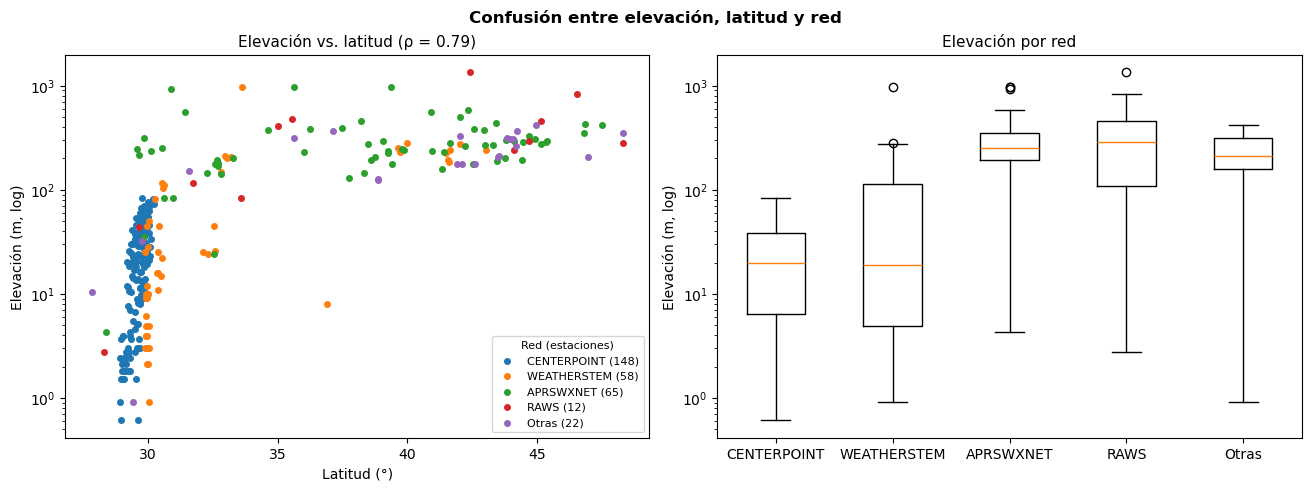

In [4]:
REDES_GRAF = ['CENTERPOINT', 'WEATHERSTEM', 'APRSWXNET', 'RAWS', 'Otras']
con_elev = datos[datos['log_elev'].notna()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for i, red in enumerate(REDES_GRAF):
    d = con_elev[con_elev['red_g'] == red]
    ax1.scatter(d['latitud'], d['elevation'], s=16, color=f'C{i}', label=f'{red} ({len(d)})')
rho, p = stats.spearmanr(con_elev['latitud'], con_elev['elevation'])
ax1.set_yscale('log')
ax1.set_xlabel('Latitud (°)')
ax1.set_ylabel('Elevación (m, log)')
ax1.set_title(f'Elevación vs. latitud (ρ = {rho:.2f})', fontsize=11)
ax1.legend(fontsize=8, title='Red (estaciones)', title_fontsize=8)

ax2.boxplot([con_elev.loc[con_elev['red_g'] == r, 'elevation'] for r in REDES_GRAF], tick_labels=REDES_GRAF)
ax2.set_yscale('log')
ax2.set_ylabel('Elevación (m, log)')
ax2.set_title('Elevación por red', fontsize=11)
fig.suptitle('Confusión entre elevación, latitud y red', fontweight='bold')
figuras['00_elevacion_latitud_red'] = fig

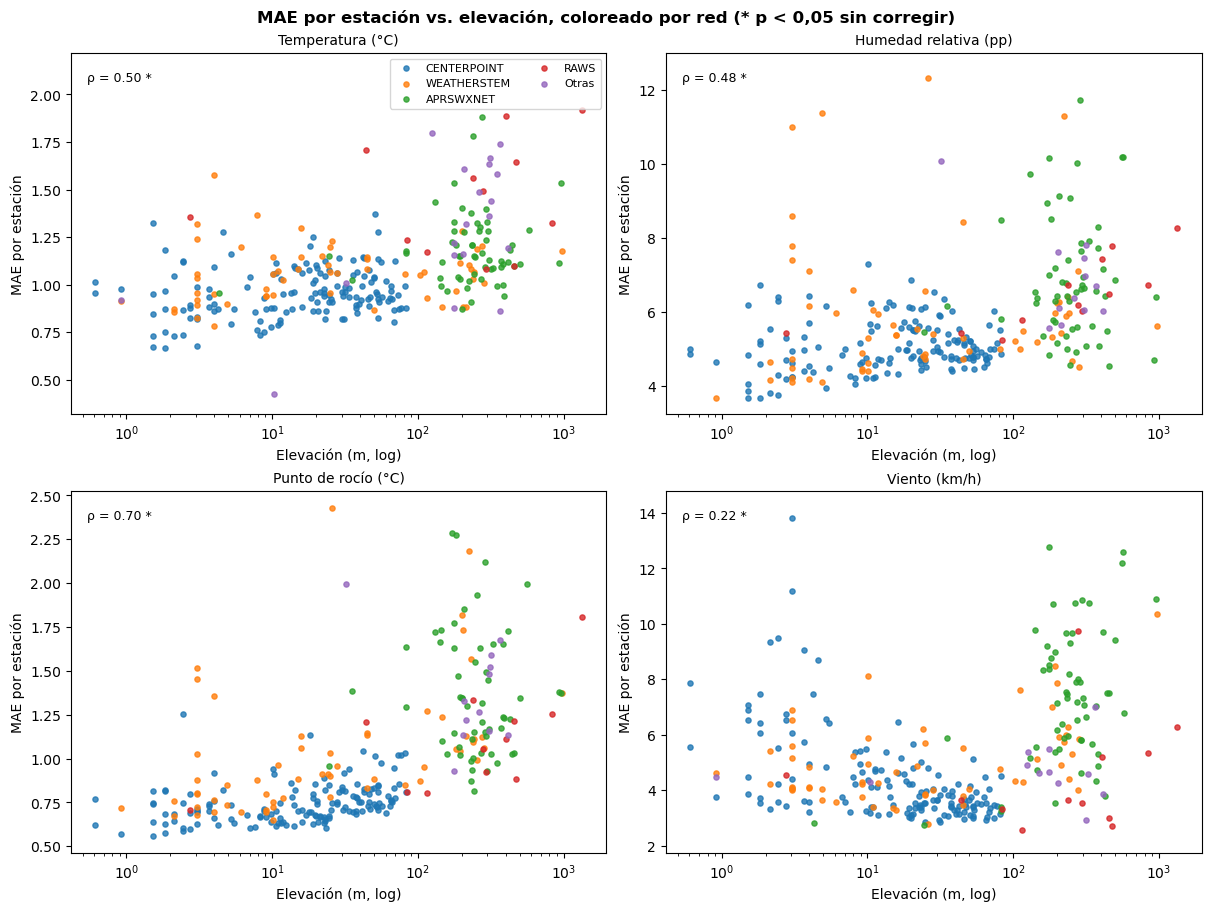

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for ax, (var, etiqueta) in zip(axes.flat, VARIABLES.items()):
    sub = con_elev[['elevation', f'abs_error_{var}', 'red_g']].dropna()  # algunas estaciones no miden esta variable
    for i, red in enumerate(REDES_GRAF):
        d = sub[sub['red_g'] == red]
        ax.scatter(d['elevation'], d[f'abs_error_{var}'], s=14, color=f'C{i}', alpha=0.8, label=red)
    rho, p = stats.spearmanr(sub['elevation'], sub[f'abs_error_{var}'])
    ax.set_xscale('log')
    ax.set_ylim(top=sub[f'abs_error_{var}'].quantile(0.99) * 1.15)  # unas pocas estaciones extremas no aplastan el resto
    ax.text(0.03, 0.95, f'ρ = {rho:.2f}' + (' *' if p < 0.05 else ''), transform=ax.transAxes, va='top', fontsize=9)
    ax.set_title(etiqueta, fontsize=10)
    ax.set_xlabel('Elevación (m, log)')
    ax.set_ylabel('MAE por estación')
axes.flat[0].legend(fontsize=8, ncol=2)
fig.suptitle('MAE por estación vs. elevación, coloreado por red (* p < 0,05 sin corregir)', fontweight='bold')
figuras['01_mae_vs_elevacion'] = fig

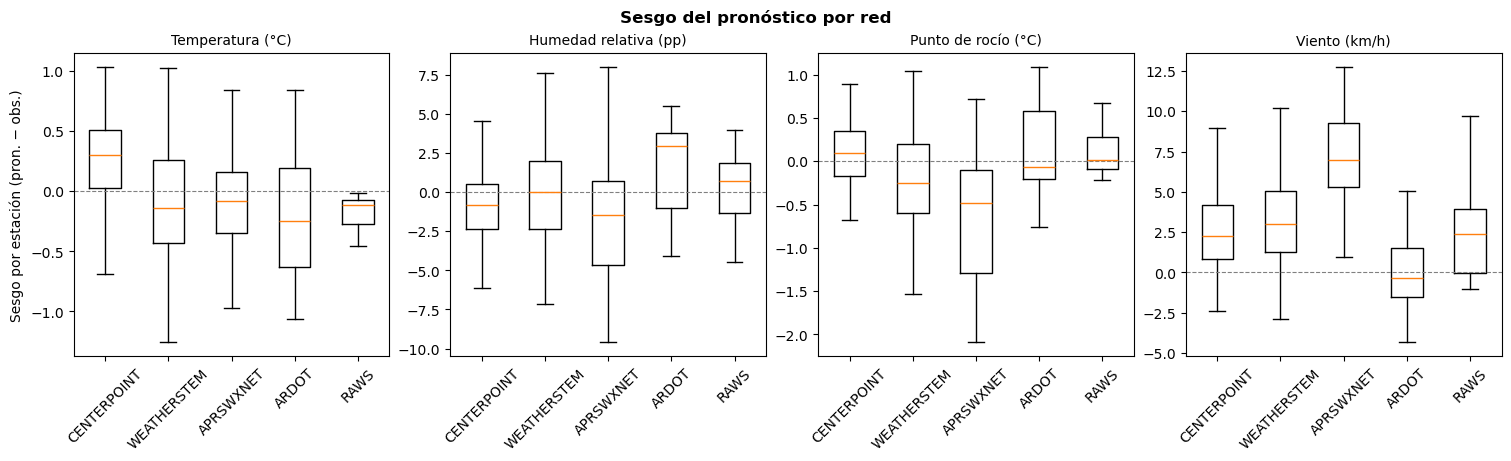

In [6]:
REDES_SESGO = ['CENTERPOINT', 'WEATHERSTEM', 'APRSWXNET', 'ARDOT', 'RAWS']  # redes con >= 10 estaciones

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), constrained_layout=True)
for ax, (var, etiqueta) in zip(axes, VARIABLES.items()):
    grupos = [datos.loc[datos['red'] == r, f'error_{var}'].dropna() for r in REDES_SESGO]
    ax.boxplot(grupos, tick_labels=REDES_SESGO, showfliers=False)
    ax.axhline(0, color='gray', lw=0.8, ls='--')
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_title(etiqueta, fontsize=10)
axes[0].set_ylabel('Sesgo por estación (pron. − obs.)')
fig.suptitle('Sesgo del pronóstico por red', fontweight='bold')
figuras['02_sesgo_por_red'] = fig

### Lectura rápida de los gráficos

- **Elevación, latitud y red van juntas**: la correlación de Spearman entre elevación y latitud es 0,79 (en las 305
  estaciones que tienen elevación), es decir, muy alta. Debajo de los 100 m casi todas las estaciones están cerca de
  los 30° de latitud (Houston y la costa del Golfo), y al norte de los 35° casi no hay estaciones bajas. La red también
  marca diferencias: CENTERPOINT y WEATHERSTEM tienen una elevación típica (mediana) de unos 20 m, y APRSWXNET, RAWS y
  "Otras", de más de 200 m. Esto hay que tenerlo en cuenta en la sección 3: si solo se mira la elevación contra el
  MAE, no se puede saber si lo que influye es la altura, la región o la red.
- **MAE vs. elevación**: en las 4 variables el MAE sube con la elevación (correlación entre 0,22 en viento y 0,71 en
  punto de rocío). Pero los colores se agrupan por zonas: los puntos de CENTERPOINT quedan abajo a la izquierda y los
  de APRSWXNET arriba a la derecha, y si se mira una sola red, la subida no es tan clara. En viento, algunas estaciones
  CENTERPOINT casi al nivel del mar tienen de los MAE más altos.
- **Sesgo por red**: en el viento el pronóstico se pasa (sesgo positivo) en todas las redes menos ARDOT, y mucho más
  en APRSWXNET (mediana ≈ +7 km/h). En temperatura y humedad las redes quedan de los dos lados del 0: CENTERPOINT se
  pasa en temperatura y se queda corta en humedad, y ARDOT hace lo contrario. A ojo, al promediar toda la región esos
  errores podrían cancelarse entre sí; hay que confirmarlo con los tests.

## 3. Pruebas de significancia

Los tests de esta sección trabajan con **rangos** (el puesto que ocupa cada valor si se los ordena de menor a mayor) en
lugar de con los valores mismos. Se eligieron porque en la Etapa A vimos que el error no tiene forma de campana
(distribución normal): hay más errores grandes de lo que esperaría una normal. Los tests basados en rangos no
necesitan que los datos sean normales y no se dejan arrastrar por unas pocas estaciones con valores muy extremos.

- **Correlación de Spearman (ρ)**: mide si, cuando una variable sube, la otra tiende a subir (o a bajar), aunque no
  sea en línea recta. Va de −1 a 1. H0: no hay relación (ρ = 0). Se usa para elevación vs. MAE de cada estación, y
  también para latitud vs. MAE como comparación: si la latitud tiene una relación igual o más fuerte que la
  elevación, es una señal de que las dos se están mezclando.
- **Wilcoxon pareado**: compara dos mediciones hechas sobre las **mismas** estaciones (es la versión con rangos del
  test t para datos apareados). H0: la diferencia típica (mediana) entre las dos mediciones es 0. Se usa para la
  variable del clima: el MAE de cada estación en las horas con probabilidad de lluvia (PoP) alta (≥ 30 %) contra el de
  sus horas con PoP baja (< 10 %). Como cada estación se compara consigo misma, no se mezclan diferencias entre
  estaciones (las del norte tienen más error y llueve distinto). Se piden al menos 20 horas en cada grupo.
- **Wilcoxon de una muestra**: prueba si la mediana de un grupo de valores es distinta de 0 (es la versión con rangos
  del test t de una muestra). H0: la mediana del sesgo es 0. Se usa para validar el sesgo: en todas las estaciones
  juntas y dentro de cada red, ¿el sesgo que se ve en el boxplot es real o podría ser casualidad?

En los tres la regla para decidir es la misma: se rechaza H0 si el p-valor (corregido, ver abajo) es menor a 0,05.

| Test | Qué compara | Qué número se informa |
|---|---|---|
| Spearman | Dos variables numéricas de las mismas estaciones | ρ: de −1 a 1; cuanto más lejos de 0, más fuerte la relación |
| Wilcoxon pareado | El MAE de cada estación con lluvia y sin lluvia | La diferencia mediana de MAE entre los dos casos |
| Wilcoxon de una muestra | El sesgo de un grupo de estaciones contra 0 | La mediana del sesgo; se exigen al menos 10 estaciones para que el test sea confiable |

**¿Por qué corregir los p-valores?** Con 12 tests en `tabla_asociacion` y 24 en `tabla_sesgo`, algunos podrían dar
"significativo" de pura casualidad: con 24 tests al 5 %, se espera más o menos 1 falso positivo. Para evitarlo se
corrigen los p-valores con el método de **Benjamini-Hochberg** (en las tablas, la columna `p_fdr`, a la que también
llamamos **q**). Este método busca que, de todos los resultados que se declaran significativos, solo una parte chica
sea por azar. Es menos estricto que Bonferroni (que divide 0,05 por la cantidad de tests), algo que conviene cuando hay
pocos cientos de estaciones.

En las dos tablas, además del p-valor, se muestra **cuánto** cambia el error (columna `efecto` o `mediana_sesgo`),
porque con muchos datos algo puede ser significativo y a la vez muy chico. La columna `n` es la cantidad de
**estaciones**, no de mediciones.

In [7]:
resultados_asociacion = []

for var, etiqueta in VARIABLES.items():
    for col, etiqueta_col in [('log_elev', 'Elevación (log)'), ('latitud', 'Latitud')]:
        sub = datos[[col, f'abs_error_{var}']].dropna()  # algunas estaciones no miden esta variable o no tienen elevación
        rho, p = stats.spearmanr(sub[col], sub[f'abs_error_{var}'])
        resultados_asociacion.append(dict(
            variable=etiqueta, atributo=etiqueta_col, tipo='Spearman (MAE)',
            efecto=round(rho, 3), p=p, n=len(sub)))

    # Variable del clima: MAE de cada estación con probabilidad de lluvia alta vs. baja
    d = mp[mp[f'abs_error_{var}'].notna()]
    baja = d[d['fcst_pop_pct'] < 10].groupby('station_id')[f'abs_error_{var}'].agg(['mean', 'size'])
    alta = d[d['fcst_pop_pct'] >= 30].groupby('station_id')[f'abs_error_{var}'].agg(['mean', 'size'])
    par = baja.join(alta, lsuffix='_baja', rsuffix='_alta', how='inner')
    par = par[(par['size_baja'] >= 20) & (par['size_alta'] >= 20)]
    _, p = stats.wilcoxon(par['mean_alta'], par['mean_baja'])
    resultados_asociacion.append(dict(
        variable=etiqueta, atributo='PoP ≥ 30 % vs. PoP < 10 %', tipo='Wilcoxon pareado (MAE)',
        efecto=round((par['mean_alta'] - par['mean_baja']).median(), 3), p=p, n=len(par)))

tabla_asociacion = pd.DataFrame(resultados_asociacion)
tabla_asociacion['p_fdr'] = multipletests(tabla_asociacion['p'], method='fdr_bh')[1]
tabla_asociacion['significativo'] = tabla_asociacion['p_fdr'] < 0.05
tabla_asociacion = tabla_asociacion.sort_values('p_fdr').reset_index(drop=True)
print(f'{tabla_asociacion["significativo"].sum()} de {len(tabla_asociacion)} tests significativos tras FDR (q < 0,05)')
tabla_asociacion.round(4)

12 de 12 tests significativos tras FDR (q < 0,05)


,variable,atributo,tipo,efecto,p,n,p_fdr,significativo
0,Punto de rocío (°C),Latitud,Spearman (MAE),0.731,0.0000,318,0.0000,True
1,Punto de rocío (°C),Elevación (log),Spearman (MAE),0.705,0.0000,286,0.0000,True
2,Temperatura (°C),PoP ≥ 30 % vs. PoP < 10 %,Wilcoxon pareado (MAE),0.700,0.0000,281,0.0000,True
3,Humedad relativa (pp),PoP ≥ 30 % vs. PoP < 10 %,Wilcoxon pareado (MAE),2.947,0.0000,270,0.0000,True
4,Viento (km/h),PoP ≥ 30 % vs. PoP < 10 %,Wilcoxon pareado (MAE),1.942,0.0000,274,0.0000,True
5,Temperatura (°C),Latitud,Spearman (MAE),0.574,0.0000,331,0.0000,True
6,Humedad relativa (pp),Latitud,Spearman (MAE),0.529,0.0000,319,0.0000,True
7,Temperatura (°C),Elevación (log),Spearman (MAE),0.502,0.0000,299,0.0000,True
8,Humedad relativa (pp),Elevación (log),Spearman (MAE),0.477,0.0000,287,0.0000,True
9,Viento (km/h),Latitud,Spearman (MAE),0.309,0.0000,325,0.0000,True


In [8]:
resultados_sesgo = []

for var, etiqueta in VARIABLES.items():
    for grupo in ['Todas'] + REDES_SESGO:
        serie = datos[f'error_{var}'] if grupo == 'Todas' else datos.loc[datos['red'] == grupo, f'error_{var}']
        serie = serie.dropna()
        serie = serie[serie != 0]  # el test de Wilcoxon no acepta valores exactamente iguales a 0
        if len(serie) < 10:
            mediana, p = np.nan, np.nan
        else:
            _, p = stats.wilcoxon(serie)
            mediana = serie.median()
        resultados_sesgo.append(dict(
            variable=etiqueta, grupo=grupo,
            mediana_sesgo=round(mediana, 3) if pd.notna(mediana) else np.nan,
            pct_sobreestima=round((serie > 0).mean() * 100, 1), n=len(serie), p=p))

tabla_sesgo = pd.DataFrame(resultados_sesgo)
valida = tabla_sesgo['p'].notna()
tabla_sesgo.loc[valida, 'p_fdr'] = multipletests(tabla_sesgo.loc[valida, 'p'], method='fdr_bh')[1]
tabla_sesgo['significativo'] = tabla_sesgo['p_fdr'] < 0.05
tabla_sesgo = tabla_sesgo.sort_values('p_fdr').reset_index(drop=True)
print(f'{tabla_sesgo["significativo"].sum()} de {valida.sum()} tests con mediana != 0 significativos tras FDR (q < 0,05)'
      f' ({(~valida).sum()} sin test por n < 10)')
tabla_sesgo.round(4)

15 de 24 tests con mediana != 0 significativos tras FDR (q < 0,05) (0 sin test por n < 10)


,variable,grupo,mediana_sesgo,pct_sobreestima,n,p,p_fdr,significativo
0,Viento (km/h),Todas,2.796,84.6,325,0.0000,0.0000,True
1,Viento (km/h),CENTERPOINT,2.275,88.5,148,0.0000,0.0000,True
2,Temperatura (°C),CENTERPOINT,0.303,79.1,148,0.0000,0.0000,True
3,Viento (km/h),APRSWXNET,7.001,100.0,62,0.0000,0.0000,True
4,Viento (km/h),WEATHERSTEM,3.000,82.8,58,0.0000,0.0000,True
5,Punto de rocío (°C),APRSWXNET,-0.478,22.8,57,0.0000,0.0000,True
6,Humedad relativa (pp),CENTERPOINT,-0.797,32.0,147,0.0001,0.0002,True
7,Temperatura (°C),Todas,0.097,56.5,331,0.0052,0.0124,True
8,Humedad relativa (pp),ARDOT,2.936,71.4,28,0.0048,0.0124,True
9,Punto de rocío (°C),CENTERPOINT,0.097,57.1,147,0.0044,0.0124,True


### Conclusiones

**Los 12 tests de relación dan significativos después de la corrección** (q < 0,05, `tabla_asociacion`):

- **Elevación**: tiene relación con el MAE de las 4 variables, y siempre en el mismo sentido (más alto, peor
  pronóstico): punto de rocío (ρ = 0,71), temperatura (ρ = 0,50), humedad (ρ = 0,48) y viento (ρ = 0,22, p = 0,0002).
  Pero la **latitud** tiene una relación igual o más fuerte en las 4 (ρ = 0,73; 0,57; 0,53 y 0,31). Como elevación y
  latitud van juntas, estos resultados no alcanzan para decir que el efecto es de la altura: eso se revisa en la
  sección 4.
- **Probabilidad de lluvia (variable del clima)**: en las 4 variables, una misma estación se equivoca más en las horas
  con PoP ≥ 30 % que en las horas con PoP < 10 % (todas p < 0,0001). La diferencia es grande en temperatura
  (+0,70 °C), humedad (+2,95 puntos de %) y viento (+1,94 km/h), y chica en punto de rocío (+0,08 °C). Es el resultado
  más claro del notebook, y coincide con lo que vimos en la Etapa A: los errores más grandes aparecían en las tormentas
  de la tarde.

**Validación del sesgo** (`tabla_sesgo`, 15 de 24 tests significativos): en el viento el pronóstico se pasa en todas
las estaciones juntas (+2,80 km/h; se pasa en el 85 % de las estaciones) y en 4 de las 5 redes (APRSWXNET +7,00 km/h,
WEATHERSTEM +3,00, RAWS +2,41 y CENTERPOINT +2,28). Solo ARDOT no tiene sesgo (−0,34 km/h, p = 0,95). Es decir, **que
el pronóstico se pase con el viento no es algo propio de una sola red ni de la zona de Houston**.
En temperatura y humedad, el sesgo de toda la región es significativo pero muy chico (+0,10 °C y −0,67 puntos de %),
tan chico que en la práctica no importa. Al separar por red se ve de dónde sale: CENTERPOINT se pasa en temperatura
(+0,30 °C, en el 79 % de sus estaciones) y se queda corta en humedad (−0,80 puntos de %), y ARDOT va al revés en
humedad (+2,94 puntos de %) y en temperatura (−0,25 °C, justo al límite de ser significativo, q = 0,045). En punto de
rocío no hay sesgo en la región (q = 0,14), salvo en APRSWXNET (−0,48 °C), lo que vuelve a sugerir problemas con los
sensores de humedad de esa red.

## 4. Control por latitud y red

La sección 2 mostró que la elevación viene "mezclada" con la latitud y con la red. Por ejemplo, `CENTERPOINT`, con 148
estaciones, es la red más grande del dataset (probablemente de CenterPoint Energy, la empresa de electricidad de
Houston), y todas sus estaciones están en esa ciudad, casi al nivel del mar. Entonces, una diferencia que parece venir
de "estar más alto" podría deberse en realidad a la red (el tipo de sensor, dónde está ubicado, cómo se calibra) o a la
región. Spearman no puede separar estas cosas, porque compara solo dos variables a la vez.

Para separarlas se usa una **regresión lineal múltiple**, que explica el MAE de cada estación con varias variables a
la vez:

$$\text{MAE} = \beta_0 + \beta_1 \log_{10}(\text{elevación}) + \beta_2\,\text{latitud} + \text{(un término por cada red)}$$

El número que interesa es $\beta_1$: cuánto cambia el MAE con la elevación **comparando estaciones de la misma latitud
y la misma red**, que es justo lo que pide la hipótesis. Como la red no es un número sino una categoría, `statsmodels`
crea una columna de 0 y 1 para cada red, y compara todas contra CENTERPOINT. Se eligió la regresión en vez de la
correlación parcial porque la regresión acepta la red (que es una categoría) sin problemas, y porque $\beta_1$ se lee
en las mismas unidades del error: "tantos °C más de MAE cada vez que la elevación se multiplica por 10".

También se calcula la regresión **simple** (solo con la elevación) para comparar: si $\beta_1$ se achica mucho al
sumar latitud y red, quiere decir que parte de lo que se veía con Spearman era en realidad efecto de esas otras dos.
H0: $\beta_1 = 0$. Los 4 p-valores de la regresión múltiple se corrigen igual que en la sección 3.

Dos columnas más de la tabla: el **intervalo de confianza del 95 %** (`ic95_multiple`) es el rango donde
probablemente está el verdadero valor de $\beta_1$; si no incluye el 0, hay efecto. El **R²** dice qué parte de las
diferencias de MAE entre estaciones explica el modelo (0 = nada, 1 = todo).

In [9]:
FORMULA_SIMPLE = 'MAE ~ log_elev'
FORMULA_MULTIPLE = "MAE ~ log_elev + latitud + C(red_g, Treatment('CENTERPOINT'))"

resultados_control = []
for var, etiqueta in VARIABLES.items():
    sub = datos[['log_elev', 'latitud', 'red_g', f'abs_error_{var}']].dropna().rename(columns={f'abs_error_{var}': 'MAE'})
    simple = smf.ols(FORMULA_SIMPLE, data=sub).fit()
    multiple = smf.ols(FORMULA_MULTIPLE, data=sub).fit()
    ic = multiple.conf_int().loc['log_elev']
    resultados_control.append(dict(
        variable=etiqueta, n=len(sub),
        beta_simple=round(simple.params['log_elev'], 3), p_simple=simple.pvalues['log_elev'],
        beta_multiple=round(multiple.params['log_elev'], 3), ic95_multiple=f'[{ic[0]:.2f}; {ic[1]:.2f}]',
        p_multiple=multiple.pvalues['log_elev'],
        r2_simple=round(simple.rsquared, 3), r2_multiple=round(multiple.rsquared, 3)))

tabla_control = pd.DataFrame(resultados_control)
tabla_control['p_fdr'] = multipletests(tabla_control['p_multiple'], method='fdr_bh')[1]
tabla_control['significativo'] = (tabla_control['p_fdr'] < 0.05) & (tabla_control['beta_multiple'] > 0)
tabla_control.round(4)

,variable,n,beta_simple,p_simple,beta_multiple,ic95_multiple,p_multiple,r2_simple,r2_multiple,p_fdr,significativo
0,Temperatura (°C),299,0.152,0.0,0.047,[-0.00; 0.10],0.0645,0.193,0.317,0.1289,False
1,Humedad relativa (pp),287,0.761,0.0,0.107,[-0.19; 0.40],0.4793,0.153,0.273,0.4793,False
2,Punto de rocío (°C),286,0.288,0.0,0.140,[0.08; 0.20],0.0000,0.365,0.537,0.0000,True
3,Viento (km/h),292,0.916,0.0,-0.306,[-0.76; 0.15],0.1833,0.087,0.307,0.2444,False


### Conclusión del control

Al comparar estaciones de la misma latitud y red, la relación con la elevación **desaparece** en temperatura, humedad y
viento:

- **Temperatura**: $\beta_1$ baja de 0,152 a 0,047 °C por cada ×10 m (p = 0,06; q = 0,13). Si queda algún efecto, es
  chico.
- **Humedad**: $\beta_1$ baja de 0,761 a 0,107 puntos de % (q = 0,48).
- **Viento**: $\beta_1$ cambia de signo, de +0,916 a −0,306 km/h (q = 0,24): a igual latitud y red, las estaciones más
  altas no se equivocan más con el viento.

El **punto de rocío** es la excepción: $\beta_1$ baja de 0,288 a 0,140 °C, pero sigue siendo significativo
(q < 0,0001) y su intervalo de confianza [0,08; 0,20] no incluye el 0. Entre dos estaciones de la misma red y latitud,
la que está 10 veces más alta (por ejemplo, a 300 m contra 30 m) tiene en promedio ≈ 0,14 °C más de MAE, cuando el MAE
típico es de ≈ 0,7 °C.

El R² sube en las 4 variables al sumar latitud y red (por ejemplo, de 0,19 a 0,32 en temperatura): esas dos variables
explican buena parte de las diferencias de error entre estaciones que, mirando solo Spearman, parecían venir de la
elevación. Es decir, lo que aparecía en `tabla_asociacion` era sobre todo un efecto de la red y la región, y no de la
altura.

## 5. Síntesis de la hipótesis

**Los datos apoyan la hipótesis solo en parte: comparando estaciones de la misma latitud y red, la elevación se
relaciona con un MAE mayor únicamente en el punto de rocío.**

1. **Elevación**: sin controlar nada, tiene relación con el MAE de las 4 variables (ρ entre 0,22 y 0,71), pero viene
   mezclada con la latitud (ρ = 0,79) y con la red. Al comparar a igual latitud y red, el efecto desaparece en
   temperatura, humedad y viento, y se mantiene en **punto de rocío** (+0,14 °C de MAE cada vez que la elevación se
   multiplica por 10). Una posible explicación, que no se puede comprobar con estos datos, es que el pronóstico se
   calcula para un cuadrado de ≈ 2,5 km de lado con una altura promedio, y en terreno con desniveles la humedad de un
   punto puntual se aleja más del promedio de ese cuadrado.
2. **Probabilidad de lluvia**: hay una relación clara y en el sentido esperado en las 4 variables (el pronóstico se
   equivoca más cuando anuncia lluvia), con diferencias grandes en temperatura, humedad y viento.
3. **Sesgo**: el resultado más firme es el del **viento**: el pronóstico se pasa por ≈ +2,8 km/h en todas las redes
   menos ARDOT. En temperatura y humedad, el sesgo de la región es significativo pero chico, y se explica sobre todo
   porque algunas redes se corren para lados opuestos (CENTERPOINT pronostica más calor y menos humedad de lo real, y
   ARDOT, más humedad).

**Limitaciones**: los datos se observaron, no salen de un experimento, así que aunque se compare a igual latitud y red
no se puede asegurar que la altura sea la *causa* de nada (puede haber otras diferencias entre estaciones, como dónde
está ubicado el sensor o cómo se lo mantiene, que vayan de la mano con la red y la elevación). Además, dentro de cada
red la elevación cambia poco, ARDOT y RDOT no tienen elevación, y hay un solo mes de datos (septiembre).

## 6. Exportación de las figuras y las tablas

In [10]:
os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_asociacion.to_csv(OUT + 'tabla_asociacion_elevacion.csv', index=False)
tabla_sesgo.to_csv(OUT + 'tabla_sesgo_direccional_elevacion.csv', index=False)
tabla_control.to_csv(OUT + 'tabla_control_latitud_red_elevacion.csv', index=False)
print(f'Guardados: {len(figuras)} figuras y 3 tablas en {OUT}')

Guardados: 3 figuras y 3 tablas en ../data/processed/hipotesis/
